# 02 · Manifold — principal-curve trajectory (whole malignant manifold)

Dong 2020's prostate malignant manifold is **non-branching**: the developmental signatures
collapse onto a **single dominant axis** — gastrulation+somitogenesis (Gast/pSom, which
**co-vary** here rather than splitting into competing arms) high over the origin, opposed to
neural-crest (Crest) at the terminal end — rather than a Puram-style hub radiating to discrete
subtypes with cross-repression. A PPT *tree* over this continuous cloud throws spurious forks;
the correct topology is a **principal curve** (ElPiGraph, non-branching by construction) fit on
the *joint* embedding — **not** a re-embedding (re-embedding an anisotropic compartment
fabricates folds; the Kürten §4 failure mode).

**Scope decision (derived, not inherited).** The manifold splits into a dominant low-cycling
**Body** and a minor **Cycling** lobe, and the Gast/pSom-high origin concentrates in the
more-proliferative side — exactly the Kürten / Lin cell-cycle-confound risk. We test it
head-on: the developmental module gene sets are essentially **cell-cycle-free** (Gast 0/81,
Crest 0/104, pSom 2/98 overlap with the Regev–Tirosh S+G2M programme), the pSom↔Crest and
Gast↔Crest anti-correlations **survive within non-cycling cells alone**, and the two low-cycling
Body lobes carry the same Gast/pSom-high means as the cycling lobe — so the axis is
developmental, not proliferative, and the **whole manifold** is kept (Bischoff / Sun / Lee /
Steele / Qian / Lin no-scoping precedent). The pseudotime↔cycling co-variation is carried as a
**caveat**, not a reason to scope out. The curve is rooted at the Gast/pSom-high origin and
pseudotime flows to the neural-crest terminus. Deliverable: `manifold.h5ad`, `manifold.pdf`.

In [1]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load processed manifold and score developmental modules
We keep all cells on their *original joint embedding coordinates* — no re-embedding. The three
embryonic signatures (Gastrulation / Somitogenesis / Neural-crest) are scored against the shared
**union** control pool and graph-smoothed to read geography rather than 10x per-cell dropout.

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells on the joint embedding')
xy = adata.obsm['X_umap']
from numpy.linalg import svd
c = xy - xy.mean(0); u,s,vt = svd(c, full_matrices=False)
print(f'UMAP principal-axis ratio (major/minor singular value): {s[0]/s[1]:.2f}')

pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
label = {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src,lab in label.items():
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]
print('raw module means (honest readout):',
      adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())

whole malignant manifold: 9698 cells on the joint embedding
UMAP principal-axis ratio (major/minor singular value): 1.09
Gast: 71/81 genes present
pSom: 83/98 genes present
Crest: 99/104 genes present
raw module means (honest readout): {'Gast': 0.035, 'pSom': 0.1004, 'Crest': -0.0406}


### Scope decision — whole manifold vs one lobe (cell-cycle confound test)
The Body / Cycling split is partly proliferative and the Gast/pSom-high origin enriches the
more-proliferative side — exactly the Kürten confound. We settle it directly: (i) the
developmental module gene sets are essentially **cell-cycle-free**; (ii) the pSom↔Crest and
Gast↔Crest spatial anti-correlations **survive within non-cycling cells alone**; (iii) the
low-cycling Body lobes carry the same Gast/pSom-high developmental means as the cycling lobe.
So the axis identity is developmental, not proliferative; we keep the **whole manifold** and
carry the pseudotime↔cycling co-variation only as a caveat.

In [4]:
print('smoothed spatial correlations on the whole manifold:')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')
print('\nper-lobe smoothed developmental means (compartment):')
print(adata.obs.groupby('compartment', observed=True)[['Gast_sm','pSom_sm','Crest_sm']].mean().round(4).to_string())
# cell-cycle-free check (Regev-Tirosh S + G2M programme)
s_genes = set(('MCM5 PCNA TYMS FEN1 MCM2 MCM4 RRM1 UNG GINS2 MCM6 CDCA7 DTL PRIM1 UHRF1 HELLS RFC2 RPA2 '
    'NASP RAD51AP1 GMNN WDR76 SLBP CCNE2 UBR7 POLD3 MSH2 ATAD2 RAD51 RRM2 CDC45 CDC6 EXO1 TIPIN DSCC1 '
    'BLM CASP8AP2 USP1 CLSPN POLA1 CHAF1B BRIP1 E2F8').split())
g2m_genes = set(('HMGB2 CDK1 NUSAP1 UBE2C BIRC5 TPX2 TOP2A NDC80 CKS2 NUF2 CKS1B MKI67 TMPO CENPF TACC3 '
    'FAM64A SMC4 CCNB2 CKAP2L CKAP2 AURKB BUB1 KIF11 ANP32E TUBB4B GTSE1 KIF20B HJURP CDCA3 HN1 CDC20 TTK '
    'CDC25C KIF2C RANGAP1 NCAPD2 DLGAP5 CDCA2 CDCA8 ECT2 KIF23 HMMR AURKA PSRC1 ANLN LBR CKAP5 CENPE CTCF '
    'NEK2 G2E3 GAS2L3 CBX5 CENPA').split())
cc = s_genes | g2m_genes
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    ov = set(feat[src]) & cc
    print(f'  {lab}: {len(ov)}/{len(set(feat[src]))} genes overlap the cell-cycle programme')
# does the axis survive in non-cycling cells?
noncyc = ~adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
for a,b in [('pSom_sm','Crest_sm'),('Gast_sm','Crest_sm')]:
    r_all = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]
    r_nc  = np.corrcoef(adata.obs.loc[noncyc.values,a], adata.obs.loc[noncyc.values,b])[0,1]
    print(f'  {a}<->{b}: all r={r_all:+.2f} | non-cycling only r={r_nc:+.2f} ({int(noncyc.sum())} cells)')
print('-> developmental axis is cell-cycle-free and survives without cycling cells; keep whole manifold (no scoping).')
sub = adata   # whole manifold is the trajectory object

smoothed spatial correlations on the whole manifold:
  Gast_sm vs pSom_sm: r = +0.90
  Crest_sm vs Gast_sm: r = -0.39
  Crest_sm vs pSom_sm: r = -0.53

per-lobe smoothed developmental means (compartment):
             Gast_sm  pSom_sm  Crest_sm
compartment                            
Body          0.0323   0.0931   -0.0387
Cycling       0.0511   0.1393   -0.0540
  Gast: 0/81 genes overlap the cell-cycle programme
  pSom: 2/98 genes overlap the cell-cycle programme
  Crest: 0/104 genes overlap the cell-cycle programme
  pSom_sm<->Crest_sm: all r=-0.53 | non-cycling only r=-0.50 (7988 cells)
  Gast_sm<->Crest_sm: all r=-0.39 | non-cycling only r=-0.31 (7988 cells)
-> developmental axis is cell-cycle-free and survives without cycling cells; keep whole manifold (no scoping).


### Fit the principal curve (ElPiGraph)
`Nodes/epg_lambda/epg_mu` give a **fold-free** monotone backbone: a node self-approach ratio
> 1 (minimum distance between graph-non-adjacent nodes, in units of median edge length)
certifies the curve does not fold back on itself. `epg_mu=100` is strong bending
regularisation, keeping the arc smooth. Fold-freeness and the 2-tip / 0-fork topology are
stable across Nodes = 15/20/30.

In [5]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med_edge = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3:
                dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med_edge, tips, forks

for Nn in [15, 20, 30]:
    a2 = sub.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.curve(a2, Nodes=Nn, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
    sa, tips, forks = fold_diag(a2)
    print(f'curve N={Nn}: {tips} tips, {forks} forks | self-approach {sa:.2f}')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(sub)
print(f'chosen curve N=20: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, 'topology check failed'

curve N=15: 2 tips, 0 forks | self-approach 2.98
curve N=20: 2 tips, 0 forks | self-approach 2.59
curve N=30: 2 tips, 0 forks | self-approach 2.32
chosen curve N=20: 2 tips, 0 forks | fold self-approach ratio = 2.59 (>1 = fold-free)


### Derive the root (data-driven)
The root is the curve tip where Gast+pSom is highest and Crest lowest — the developmental
origin. Pseudotime then flows to the neural-crest terminus.

In [6]:
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values
print('gradient along pseudotime (Spearman rho on smoothed):')
for s_ in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,p = spearmanr(t, sub.obs[s_]); print(f'  {s_}: rho={rho:+.3f} p={p:.1e}')
tn = (t-t.min())/(t.max()-t.min())
for m,lab_ in [('Crest_sm','Neural-crest'),('pSom_sm','Somitogenesis'),('Gast_sm','Gastrulation')]:
    hi = sub.obs[m] >= sub.obs[m].quantile(0.9)
    print(f'{lab_}-high decile mean pseudotime = {tn[hi.values].mean():.2f}')
# caveat: does pseudotime co-vary with cycling?
g2m = pd.to_numeric(sub.obs['g2m_score'], errors='coerce').fillna(0).values
g1s = pd.to_numeric(sub.obs['g1s_score'], errors='coerce').fillna(0).values
cyc = np.maximum(g1s, g2m)
rho_c,_ = spearmanr(t, cyc); print(f'caveat: pseudotime vs cycling score rho = {rho_c:+.2f} '
      '(cycling pole sits at the developmental origin; a biology property, not an axis artefact)')

tip 0: Gast=+0.0206 pSom=+0.0711 Crest=-0.0190
tip 2: Gast=+0.0563 pSom=+0.1364 Crest=-0.0604
derived root = tip 2 (Gast/pSom-high, Crest-low)
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho=-0.581 p=0.0e+00
  pSom_sm: rho=-0.714 p=0.0e+00
  Crest_sm: rho=+0.794 p=0.0e+00
Neural-crest-high decile mean pseudotime = 0.98
Somitogenesis-high decile mean pseudotime = 0.20
Gastrulation-high decile mean pseudotime = 0.18
caveat: pseudotime vs cycling score rho = -0.24 (cycling pole sits at the developmental origin; a biology property, not an axis artefact)


### House orientation (re-used from 01, verified against pseudotime)
The house orientation — a single rigid rotation of the developmental axis to horizontal — was
derived **once in 01** (rotation angle from the manifold's axis of maximal variance; sign set
from the developmental-module geography, Gast/pSom-high origin on the left) and stored as
`X_umap_lin`. Every UMAP deliverable across 01–04 re-uses these exact coordinates, so
orientation is consistent by construction (binding). Here we **verify** that layout now that
pseudotime exists: the correlation of the stored `X_umap_lin` x-axis with pseudotime must be
strongly positive (low pseudotime = developmental origin on the left).

In [7]:
t = sub.obs['t'].values
r = float(np.corrcoef(sub.obsm['X_umap_lin'][:,0], t)[0,1])   # re-used from 01, not re-derived
c = sub.obsm['X_umap'] - sub.obsm['X_umap'].mean(0)
dirv = np.array([np.cov(c[:,0], t)[0,1], np.cov(c[:,1], t)[0,1]])
_, _, vt = np.linalg.svd(c, full_matrices=False)
dang = abs(np.degrees(np.arctan2(dirv[1],dirv[0]) - np.arctan2(vt[0,1],vt[0,0]))) % 180
dang = min(dang, 180-dang)
assert r > 0.5, f'stored orientation not pseudotime-consistent (corr={r:.2f})'
print(f'house orientation re-used from 01 (X_umap_lin); corr(x_lin, pseudotime) = {r:+.2f}')
print(f'variance-axis vs pseudotime-axis disagreement = {dang:.1f}deg (small -> equivalent orientation)')

house orientation re-used from 01 (X_umap_lin); corr(x_lin, pseudotime) = +0.85
variance-axis vs pseudotime-axis disagreement = 14.5deg (small -> equivalent orientation)


### Save manifold + trajectory figure (deliverable)
House style: `figsize=(3.5,1.5)`, pseudotime left→right on `X_umap_lin`, cividis, external
colorbar. Pseudotime runs from the Gast/pSom-high origin (left) to the neural-crest terminus
(right).

saved manifold.h5ad + manifold.pdf


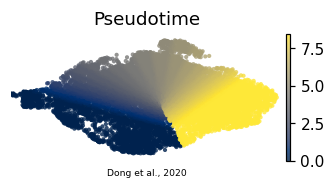

In [8]:
# sanitize non-serializable ElPiGraph uns entry (node positions kept; graph lives in uns['graph'])
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = sub.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Dong et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf')